### 💡 Outlier Analysis : 이상치 분석
이상치는 대부분의 데이터와 비교했을 때 유독 크거나 작은 값을 의미한다.

```python
fares = [10, 15, 20, 25, 30, 35, 40, 500]
```

대부분의 요금은 10 ~ 40 사이인데, 500이라는 큰 값을 **이상치**라고 한다.

그렇지만 이상치라고 해서 잘못 기록된 값은 아니다.

- 이상치 = 다른 데이터와 크게 차이가 나는 값
- 오류 데이터 = 실제로 잘못 기록된 값

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

df = pd.read_csv("./datasets/titanic.csv")

#### 실제 타이타닉 데이터셋을 이용해서 이상치 찾아보기

In [11]:
# 이상치 탐지 함수
def detect_outlier(column, df):

    # Q1, Q3 계산
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    # IQR 계산
    IQR = Q3 - Q1

    # 하안값, 상안값 계산
    lower = Q1 - (1.5 * IQR)
    upper = Q3 + (1.5 * IQR)

    # 이상치 탐지
    outliers = df[(df[column] < lower) | (df[column] > upper)]

    return outliers, outliers.shape[0]


# 나이 이상치 탐지 확인
age_outliers, age_outliers_count = detect_outlier("age", df)
print(age_outliers)
print(age_outliers_count)


     survived  pclass   sex   age  sibsp  parch     fare embarked   class  \
33          0       2  male  66.0      0      0  10.5000        S  Second   
54          0       1  male  65.0      0      1  61.9792        C   First   
96          0       1  male  71.0      0      0  34.6542        C   First   
116         0       3  male  70.5      0      0   7.7500        Q   Third   
280         0       3  male  65.0      0      0   7.7500        Q   Third   
456         0       1  male  65.0      0      0  26.5500        S   First   
493         0       1  male  71.0      0      0  49.5042        C   First   
630         1       1  male  80.0      0      0  30.0000        S   First   
672         0       2  male  70.0      0      0  10.5000        S  Second   
745         0       1  male  70.0      1      1  71.0000        S   First   
851         0       3  male  74.0      0      0   7.7750        S   Third   

     who  adult_male deck  embark_town alive  alone  
33   man        True 

#### Box Plot으로 이상치 시각화

/var/folders/9l/m6x_j6b56sx5h8gg924xyt2w0000gn/T/ipykernel_49292/4039882283.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


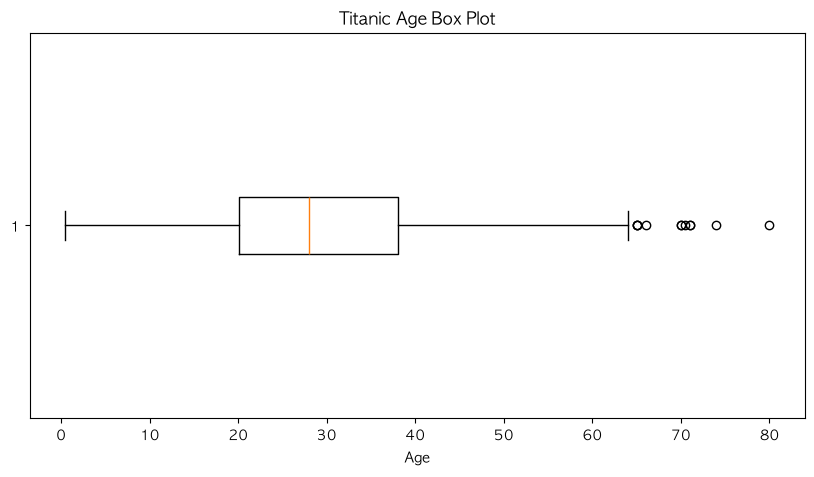

In [12]:
plt.figure(figsize=(10, 5))

plt.boxplot(
    df["age"].dropna(),
    vert=False
)

plt.title("Titanic Age Box Plot")
plt.xlabel("Age")

plt.show()